В цьому ноутбуці наглядно демонструєтся робота бектест алгоритму на всій доступній історії аткиву

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
stock = 'ETH'
prices = df_stocks[stock].dropna()

In [5]:
strategy = {
    "buy_amount": 10,
}

01:11:23 - cmdstanpy - INFO - Chain [1] start processing
01:11:24 - cmdstanpy - INFO - Chain [1] done processing


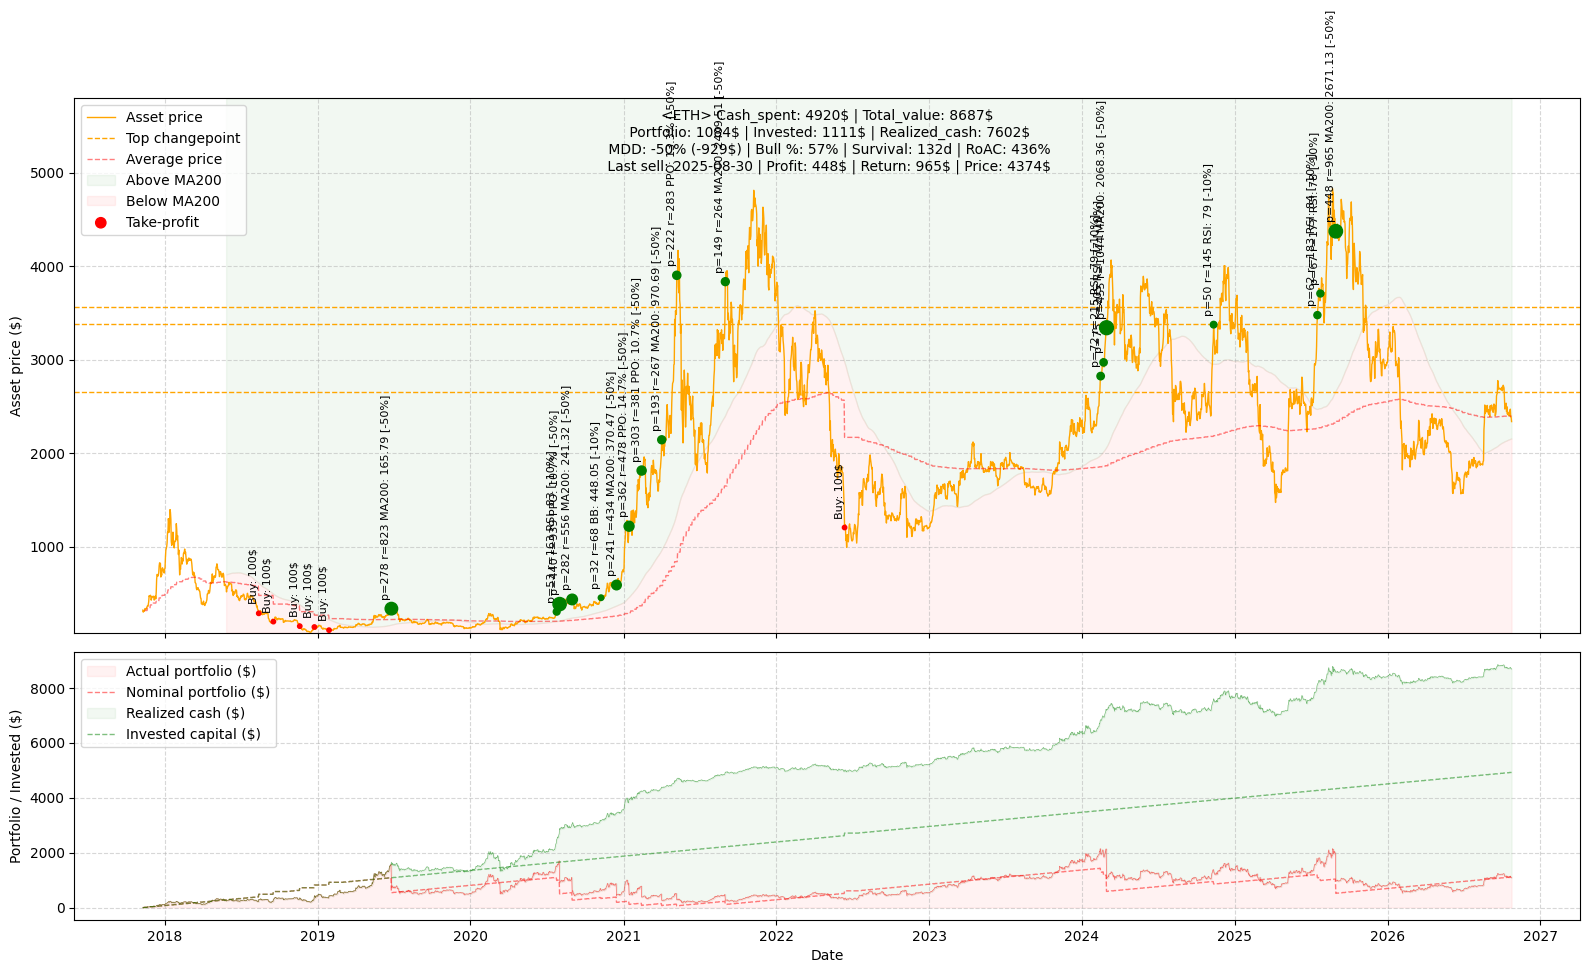

In [6]:
bt = BacktestDCA(
target=stock,
prices=prices,
strategy=strategy
)
result, metrics = bt.run()
ploter(metrics=metrics, history=result)

In [7]:
metrics

{'Target': 'ETH',
 'Cash_spent': 4920,
 'Realized_cash': 7602,
 'Portfolio': 1084,
 'Invested': 1111,
 'Total_value': 8687,
 'Bull_history': 57,
 'Avg_price': np.float64(2396.0973749036516),
 'Num_take_profits': 24,
 'MDD': -50,
 'MDD_usd': -929,
 'MA200_survival_days': 132.42857142857142,
 'RoAC': 436}

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2017-11-09,320.884003,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-11-10,299.252991,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-11-11,314.681000,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-11-12,307.907990,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-11-13,316.716003,0.031258,9.900000,9.9,0.0,0.0,0.000000,,9.900000,316.716003,9.900000
...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,2446.730713,0.464015,1111.824386,4920.3,0.0,0.0,7602.582389,,1135.318999,2396.097375,8737.901388
2026-10-21,2470.766113,0.464015,1111.824386,4920.3,0.0,0.0,7602.582389,,1146.471778,2396.097375,8749.054167
2026-10-22,2386.189209,0.464015,1111.824386,4920.3,0.0,0.0,7602.582389,,1107.226852,2396.097375,8709.809241
